# Problemas evaluados y por qué se descartaron

Antes de llegar a la demanda eléctrica se evaluaron otros cuatro problemas con el mismo protocolo: partición cronológica, líneas base tradicionales, modelos lineal, no lineal e híbrido, y prueba de Diebold-Mariano. Para el proyecto final se fijaron cuatro **criterios de admisión**, iguales para todos los candidatos:

| Criterio | Exigencia |
|---|---|
| C1 | Datos reales con 20.000 observaciones o más |
| C2 | El mejor modelo de Machine Learning reduce el error de la mejor línea base tradicional en 10 % o más |
| C3 | La mejora es estadísticamente significativa en la prueba (Diebold-Mariano, p < 0,05) en el horizonte que importa |
| C4 | La regla de elección fijada de antemano no elige un modelo tradicional |

Las cifras se leen de los archivos de resultados de cada proyecto (`datos_descartados/`); las de la lluvia se transcriben del Jupyter Book del Entregable 2.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src"); import estilo_tablas; estilo_tablas.activar()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 120)
R = "../resultados/"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
ORIG = "ATER (modelo original)"
COL = {"Persistencia (misma hora de ayer)": "#9AA5A0", "Estacional (misma hora semana pasada)": "#B8C2BD", "Promedio por hora y día": "#D5DBD8",
       "Ridge (lineal)": "#5B7F96", "Random forest (relativo)": "#1F5A3A", "XGBoost (relativo)": "#C8892B",
       "Híbrido Ridge + XGBoost (residuo relativo)": "#8E4B7A", ORIG: "#C0392B"}

In [2]:
t = pd.read_csv(R + "problemas_descartados.csv")
t[["orden", "problema", "datos", "n_datos", "mejor_ML", "linea_base", "mejora_pct", "p_DM", "C1", "C2", "C3", "C4", "criterios_cumplidos"]].round(1)

orden,problema,datos,n_datos,mejor_ML,linea_base,mejora_pct,p_DM,C1,C2,C3,C4,criterios_cumplidos
1,Lluvia semanal en Sabanagrande (Entregables 1 y 2),NASA POWER diario 1981–2025,16.436,SVR lineal / híbrido SVR + RF,Climatología,7.000000,significativo solo a 1 semana,False,False,False,True,1
2,"Precio mensual del maíz amarillo (SIPSA, 61 mercados)",SIPSA 2014–2026,8.658,Random forest,Persistencia,11.600000,"p = 0,509 a 4 meses (a 1 mes: 13,1 %, p = 0,026)",False,True,False,False,1
3,Decisión de siembra de maíz (beneficio por fecha de siembra),Precio SIPSA + costos + rendimiento,42,Random forest,Persistencia,-7.200000,-,False,False,False,False,0
4,Baloto (¿qué balotas saldrán?),Simulación con las reglas reales (5 de 43 + 1 de 16),107.500,Ridge (lineal),Promedio,0.200000,"AUC entre 0,492 y 0,504",True,False,False,False,1
5,Demanda eléctrica horaria de Air-e con el calor de Sabanagrande (DEFINITIVO),XM (Sinergox) + NASA POWER horario 2020–2026,52.272,ATER (modelo original),Persistencia (misma hora de ayer),65.400000,p ajustado (Holm) = 2.0e-51,True,True,True,True,4


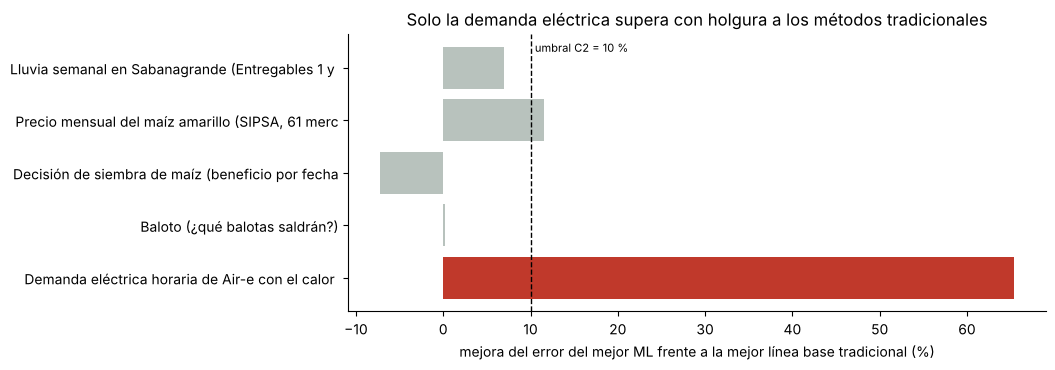

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
cols = ["#B8C2BD"] * 4 + ["#C0392B"]
ax.barh(t.problema.str.slice(0, 48)[::-1], t.mejora_pct[::-1], color=cols[::-1])
ax.axvline(10, color="k", ls="--", lw=1); ax.text(10.5, 4.3, "umbral C2 = 10 %", fontsize=8)
ax.set_xlabel("mejora del error del mejor ML frente a la mejor línea base tradicional (%)")
ax.set_title("Solo la demanda eléctrica supera con holgura a los métodos tradicionales"); plt.show()

In [4]:
for _, r in t.iterrows():
    print(f"{r.orden}. {r.problema}\n   → {r.veredicto}\n")

1. Lluvia semanal en Sabanagrande (Entregables 1 y 2)
   → Mejor, pero no representativo: mejora de 7 % (< 10 %) y significativa solo a 1 semana; a 2–4 semanas no supera a la climatología con significancia.

2. Precio mensual del maíz amarillo (SIPSA, 61 mercados)
   → Un modelo tradicional gana: la regla de validación eligió «Estacional»; a 4 meses (horizonte de cosecha) el RF no es significativo y hay menos de 20.000 datos.

3. Decisión de siembra de maíz (beneficio por fecha de siembra)
   → Un modelo tradicional gana: la persistencia tiene el menor error del precio a la cosecha (MAPE 10,4 % frente a 10,5 % del RF) y todos los modelos, incluido el oráculo, siembran las mismas fechas: el pronóstico no cambia la decisión.

4. Baloto (¿qué balotas saldrán?)
   → Imposible por diseño: el sorteo es aleatorio; ningún modelo supera al promedio (AUC ≈ 0,50).

5. Demanda eléctrica horaria de Air-e con el calor de Sabanagrande (DEFINITIVO)
   → Cumple los cuatro criterios: gana a todos los mo

## Lectura

1. **Lluvia semanal (Entregables 1 y 2): mejor, pero no representativa.** El modelo de ML mejora 7 % el error de la climatología a una semana (IC 95 %: 3,7–10,7 %), pero esa ventaja solo es significativa a una semana; a dos, tres y cuatro semanas no supera a la climatología con significancia. Además, la serie tiene 16.436 días (menos de 20.000) y la mejora queda por debajo del 10 %.
2. **Precio del maíz: lo gana un modelo tradicional.** La regla de validación eligió el **modelo estacional**. En la prueba, el random forest reduce el error 11,6 % a cuatro meses (el horizonte de la cosecha), pero sin significancia (p = 0,51), y el panel tiene 8.658 precios.
3. **Decisión de siembra: lo gana un modelo tradicional.** La **persistencia** tiene el menor error del precio a la cosecha (MAPE 10,4 % frente a 10,5 % del random forest), y todos los modelos, incluido el oráculo que conoce el precio real, recomiendan sembrar en las mismas 24 de 42 fechas: el pronóstico no cambia la decisión.
4. **Baloto: imposible por diseño.** El sorteo es aleatorio; con más de 100.000 filas, todos los AUC quedan en 0,50 ± 0,01 y ningún modelo supera al promedio. Sirvió como control de que el protocolo no "encuentra" patrones donde no los hay.
5. **Demanda eléctrica de Air-e con el calor de Sabanagrande (definitivo).** Es el único problema que cumple los cuatro criterios: 52.272 horas reales, mejora de 65 % frente a la persistencia, significativa en todas las pruebas, y la regla elige un modelo de Machine Learning. Sobre él se construyó el modelo original de los capítulos 5 y 6, que además le gana a los modelos de Machine Learning conocidos.